<a href="https://colab.research.google.com/github/Nasim-Amani/ramp-aware-solar/blob/main/Pre_E3_updated_RQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Research roadmap: fair evaluation and training of solar ramp forecasts

This notebook explains, step by step:
1. **what our own experiments taught us** (data exploration, E1, E2 and the ramp-risk test),
2. **what other researchers have found** about ramps, in solar, wind and other time series,
3. **the gap** we found and our **main contribution**,
4. **the roadmap**: what we do next, *where in the code*, and *which parts come from other papers and which are our own*.

**What is a ramp?** A ramp is a sudden, large change in power or irradiance, e.g. a cloud covers the sun and irradiance falls by half within seconds. In our work, a ramp is a 10-s change of irradiance larger than **80 W/m²** (the 95th percentile of the 10-s changes on the broken-cloud training days).

## Part 1. What our experiments taught us

### 1.1 Data exploration (1-s irradiance, Sohar University, 11 days, Feb 2013)
- **Ramps are real.** An independent sensor (PV module 2 current) changed in the same direction at **98.8 %** of the ramp steps.
- **Ramps are fast and short.** 72 % of the ramp events are completed within one 10-s step, and the sun stays blocked for a median of only **20 s**.
- **Ramps come in groups.** Clear days have no ramps; 98 % of all ramp steps occur on the four broken-cloud days. Restless periods last for many minutes.
- **The chance of a ramp is predictable, its timing is not.** A ramp followed in the next 60 s in only **3 %** of the cases after a calm period, but in **55 %** after many recent ramps. The direction of the next change, however, cannot be predicted from past changes.

### 1.2 E1 / E1b: the standard LSTM and a "ramp-aware" loss (3 seeds)
We trained a simple LSTM (input: last 10 min of 10-s irradiance; output: the next 6 values, 10–60 s ahead).
- **Trained with MSE, the LSTM is blind to ramps:** it caught only **5 ± 3** of the 1500 ramp steps on the broken-cloud test day (250 separate ramps, each seen in 6 overlapping forecasts).
- **With an extra "ramp term" in the loss** (λ = 1; the gradient difference loss of Mathieu et al., 2016), it caught **178 ± 44** ramp steps, about 35 times more, but with many false alarms (precision 0.26) and lower accuracy (RMSE about equal to persistence instead of 4 % better).
- **The models mostly catch the sun returning, not the cloud arriving:** rises were caught about twice as often as drops.
- Predicting the change instead of the value did not help.

### 1.3 E2: the weight λ of the ramp term
- **More λ means more ramps caught but lower accuracy.** No λ kept the accuracy of plain MSE while catching a useful share of ramps.
- **The key observation:** looking at whole forecast paths (now → +60 s), the ramp-aware model does **not** predict one clear jump. It predicts **many medium jumps up and down (a zigzag)**. Some of these jumps happen to lie within ±10 s of a real ramp, so the ramp score counts them as "caught". **Part of the improvement is luck, not foresight.**

### 1.4 Ramp-risk test: the chance of a ramp in the next 60 s
- The chance of a ramp can be forecast well (ROC-AUC up to **0.93**, reliable probabilities).
- A simple logistic regression on three variability features did better than the LSTM.
- The risk rises only **after** the first ramp of a restless period: the models recognise that a restless period continues, not that it is about to begin.


**Together, these results lead to one question:** if a model can raise its ramp score by zigzagging, *how much of a "better ramp score" is real?* This question is the starting point of our paper.

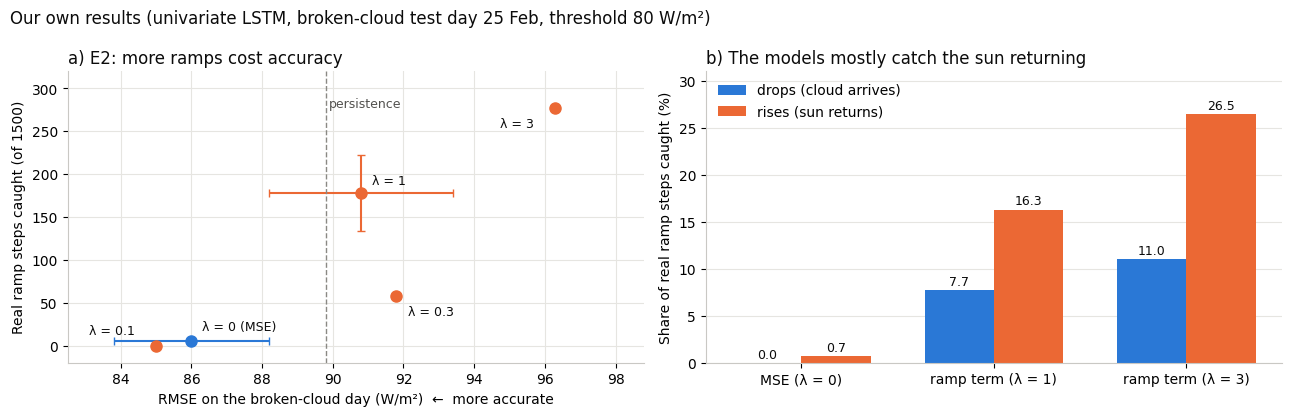

In [1]:
# Figure: our own E2 results (numbers copied from the E1/E2 result tables)
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c4", "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})
INK, MUTED, BLUE, ORANGE, GRAY = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#8a8984"
# E2 results (broken-cloud day): λ, RMSE, sd, ramps caught, sd
pts = [("λ = 0 (MSE)", 86.0, 2.2, 5, 3), ("λ = 0.1", 85.0, None, 0, None), ("λ = 0.3", 91.8, None, 58, None),
       ("λ = 1", 90.8, 2.6, 178, 44), ("λ = 3", 96.3, None, 277, None)]
off = {"λ = 0 (MSE)": (8, 8), "λ = 0.1": (-48, 8), "λ = 0.3": (8, -14), "λ = 1": (8, 6), "λ = 3": (-40, -14)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, x, xs, y, ys in pts:
    ax[0].errorbar(x, y, xerr=xs, yerr=ys, fmt="o", ms=8, capsize=3, color=BLUE if "MSE" in name else ORANGE)
    ax[0].annotate(name, (x, y), xytext=off[name], textcoords="offset points", fontsize=9, color=INK)
ax[0].axvline(89.8, color=GRAY, ls="--", lw=1); ax[0].text(89.9, 290, "persistence", color=MUTED, fontsize=9, va="top")
ax[0].set_xlim(82.5, 98.8); ax[0].set_ylim(-20, 320)
ax[0].set_xlabel("RMSE on the broken-cloud day (W/m²)  ←  more accurate")
ax[0].set_ylabel("Real ramp steps caught (of 1500)")
ax[0].set_title("a) E2: more ramps cost accuracy", loc="left", color=INK)

labels = ["MSE (λ = 0)", "ramp term (λ = 1)", "ramp term (λ = 3)"]
drops, rises = [0.0, 7.7, 11.0], [0.7, 16.3, 26.5]
xpos = range(len(labels)); w = 0.36
b1 = ax[1].bar([i - w/2 for i in xpos], drops, w, color=BLUE, label="drops (cloud arrives)")
b2 = ax[1].bar([i + w/2 for i in xpos], rises, w, color=ORANGE, label="rises (sun returns)")
for bars in (b1, b2):
    for b in bars:
        ax[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"{b.get_height():.1f}", ha="center", fontsize=9, color=INK)
ax[1].set_xticks(list(xpos)); ax[1].set_xticklabels(labels)
ax[1].set_ylabel("Share of real ramp steps caught (%)"); ax[1].set_ylim(0, 31)
ax[1].grid(axis="x", visible=False); ax[1].legend(frameon=False)
ax[1].set_title("b) The models mostly catch the sun returning", loc="left", color=INK)
fig.suptitle("Our own results (univariate LSTM, broken-cloud test day 25 Feb, threshold 80 W/m²)", x=0.01, ha="left", color=INK)
plt.tight_layout(); plt.show()

## Part 2. What other researchers have found (in simple words)

**1. Ramps have been studied for many years, mostly for wind power.**
Reviews of wind ramp forecasting (Gallego-Castillo et al., 2015) report the same problem we found: a model tuned to be good *on average* (low RMSE) is poor at ramps, and it is hard to make a model good at both. Timing errors are punished heavily. A recent review of wind *and* solar ramps (Zhang et al., 2025) says there is still **no agreed way to measure ramp forecasts** and calls for **ramp-specific metrics and loss functions**.

**2. Because timing is so hard, many researchers forecast the *chance* of a ramp.**
In wind power, ramps are often forecast as probabilities, e.g. from many possible future scenarios (Cui et al., 2017; Bossavy, Girard & Kariniotakis). This matches our own finding: the chance is predictable, the exact timing is not.

**3. In solar forecasting, ramp scores are new and spreading.**
Nouri et al. (2024) showed that a model with good RMSE detected ramps poorly (F1 = 0.14) and proposed a ramp score: precision, recall and F1, where a predicted ramp counts as correct if a real ramp occurs within a small time window. Benchmarks such as SolarBench (2026) now report ramp detection as well. Methods that improve ramps mostly use sky cameras or generative models.

**4. Generous scores can be fooled — a lesson from another field.**
In anomaly detection (finding unusual moments in time series), a generous scoring rule counted a whole event as found if one point hit it. Kim et al. (2022, AAAI) showed that **even random guesses could reach top scores** with this rule. Their advice: always compare a model with a **random guesser**, and use stricter scores. Tatbul et al. (2018, NeurIPS) proposed event scores in which **one real event can be matched to only one prediction**, and extra predictions are penalised. In wind ramp forecasting, Meng et al. (2025) warn that large time windows can "inflate forecast skill".

**5. Special losses have been proposed against smoothing.**
- The gradient difference loss (Mathieu et al., 2016) asks for changes of the right size — this is our current ramp term.
- DILATE (Le Guen & Thome, 2019) and TILDE-Q (Lee et al.) compare the shape of a forecast.
- The Extreme Value Loss (Ding et al., 2019) adds a separate yes/no output for extreme events.
- Subich et al. (2025) compare the *size* of features independently of their *position* (in weather maps).

**What this means for us:** others have shown that RMSE hides ramps, that ramp scores are needed, and that generous event scores can be fooled in other fields. **Nobody has shown that a ramp-aware training loss can fool a ramp score through zigzag forecasts** — which is what our E2 results suggest.

## Part 3. The gap and our main contribution

**The gap:** ramp scores with a time window (Nouri et al., 2024) and "sharpening" losses (e.g. Mathieu et al., 2016) are both being adopted, but their combination has not been tested. Our results suggest that a model can raise its ramp score by zigzagging.

**Main contribution of the paper:**
> *Ramp forecasts must be evaluated and trained fairly. We show that a common ramp-aware loss can fool a common ramp score through zigzag forecasts, propose a fair way to score ramp forecasts, and test a simple loss that rewards one real jump instead of many wiggles.*

The figure below illustrates the idea with made-up numbers: (a) MSE spreads the drop out; (b) the current ramp term produces medium jumps everywhere, some of which fall into the ±10 s window by luck; (c) the goal is one jump of the right size, even if slightly early.


**Why this is useful (not only new):** more and more researchers report ramp scores. If their improvements are partly luck, the field needs to know how to check this and how to train models that really improve.

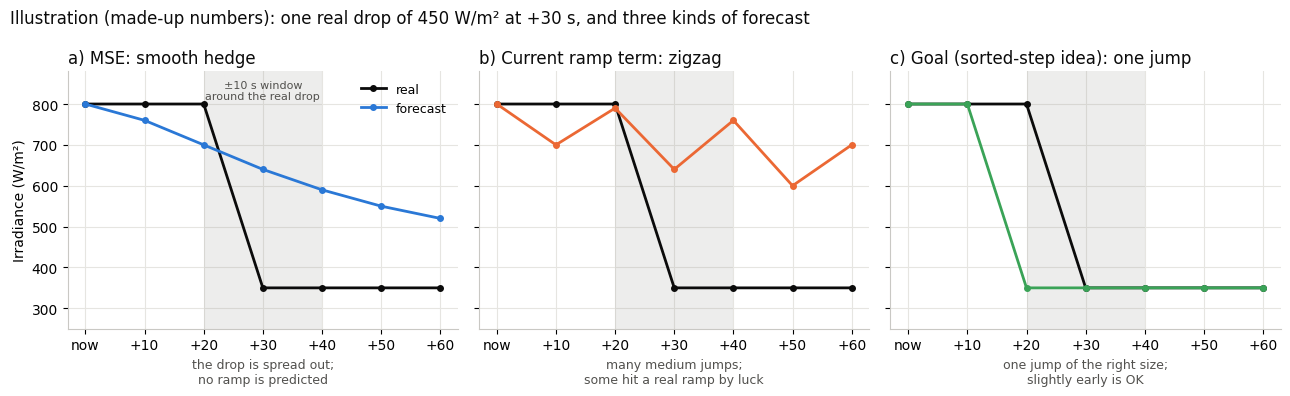

In [2]:
# Illustration with made-up numbers: one real drop and three kinds of forecast
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c4", "axes.grid": True, "grid.color": "#e6e5e1",
                     "axes.axisbelow": True})
INK, MUTED = "#0b0b0b", "#52514e"
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#3aa357", "#8a8984"

t = np.arange(0, 70, 10)                       # now, +10 ... +60 s
real   = np.array([800, 800, 800, 350, 350, 350, 350])
mse    = np.array([800, 760, 700, 640, 590, 550, 520])
zigzag = np.array([800, 700, 790, 640, 760, 600, 700])
sorted_= np.array([800, 800, 350, 350, 350, 350, 350])

fig, ax = plt.subplots(1, 3, figsize=(13, 4.0), sharey=True)
panels = [("a) MSE: smooth hedge", mse, BLUE, "the drop is spread out;\nno ramp is predicted"),
          ("b) Current ramp term: zigzag", zigzag, ORANGE, "many medium jumps;\nsome hit a real ramp by luck"),
          ("c) Goal (sorted-step idea): one jump", sorted_, GREEN, "one jump of the right size;\nslightly early is OK")]
for a, (title, f, c, note) in zip(ax, panels):
    a.axvspan(20, 40, color=GRAY, alpha=0.15, lw=0)
    a.plot(t, real, "-o", color=INK, lw=2, ms=4, label="real")
    a.plot(t, f, "-o", color=c, lw=2, ms=4, label="forecast")
    a.set_title(title, loc="left", color=INK)
    a.set_xticks(t); a.set_xticklabels(["now", "+10", "+20", "+30", "+40", "+50", "+60"])
    a.set_xlabel(note, fontsize=9, color=MUTED)
    a.set_ylim(250, 880)
ax[0].set_ylabel("Irradiance (W/m²)")
ax[0].legend(loc="upper right", frameon=False, fontsize=9)
ax[0].text(30, 860, "±10 s window\naround the real drop", ha="center", va="top", fontsize=8, color=MUTED)
fig.suptitle("Illustration (made-up numbers): one real drop of 450 W/m² at +30 s, and three kinds of forecast",
             x=0.01, ha="left", color=INK)
plt.tight_layout(); plt.show()

## Part 4. Roadmap

The first paper is kept small and safe: three steps, all on our own dataset. Steps 1 and 2 need **no new training**: they reuse the forecasts already saved in E1 and E2 (the `pred_*.npy` files). Only Step 3 trains new models.

---

### Step 1. Can a forecast that knows nothing get a good ramp score?

**Goal:** find out whether the current ramp score can be fooled.

**Why:** in E2 we saw that the ramp-aware model predicts many jumps up and down (zigzag), and some of them count as "caught ramps" only because they fall within ±10 s of a real ramp. If that is luck, a forecast with *random* jumps should also score well.

**What we do:**
1. Make a **random guesser**: it starts from persistence (the current value) and adds random jumps up or down along the forecast path, about as big and as frequent as the jumps of the ramp-aware model. It knows nothing about the sky.
2. Score it with the **current ramp score** (the same one used in E1 and E2).
3. Compare its score with our trained models.

*Example:* if the random guesser catches 120 of the 1500 ramp steps and the ramp-aware model 178, then most of the model's "improvement" could be reached by luck alone.

**What we expect:** the random guesser scores clearly above 0 — showing that the current score rewards jumping around.

**Where in the code:** new notebook `E4_Fair_Ramp_Score.ipynb`
- `widen()` and `ramp_counts()` — the current ramp score, copied unchanged from E1/E2
- `random_guesser()` — new function that makes the random forecast

**Whose idea:**
- Current ramp score: **Nouri et al. (2024)**
- Comparing with a random guesser: **Kim et al. (2022)**, who showed that random guesses could fool a generous score in anomaly detection
- A random guesser made of random jumps along a forecast path: **ours**

---

### Step 2. A fair ramp score

**Goal:** a score that rewards real foresight, not luck.

**Why:** the current score lets one real ramp be "caught" by several predicted jumps, and it does not show how much a forecast zigzags.

**What we do:** we score all saved forecasts (and the random guesser) again, with four new rules:
1. **One prediction per real ramp.** Each real ramp can be matched to only one predicted ramp; any extra predicted ramps count as **false alarms**.
   *Example:* three predicted jumps around one real drop → 1 hit + 2 false alarms (now: possibly 3 hits).
2. **Right direction.** A predicted rise next to a real drop does not count. (The current score already checks this; we keep it.)
3. **Zigzag index.** For each model: how often its forecast paths change direction, compared with the real paths. A model that zigzags much more than the sky does is suspicious.
4. **First ramp vs later ramps.** We score separately (a) the **first** ramp after 5 calm minutes — a real warning — and (b) ramps **inside** a restless period, which are much easier.

The result is one table: every model and the random guesser, with the **old score next to the new score**.

**What we expect:** with the new score, the ramp-aware model's advantage shrinks, and the random guesser falls close to zero.

**Where in the code:** `E4_Fair_Ramp_Score.ipynb`
- `match_one_to_one()` — new matching rule (replaces `widen()` in the new score), including the direction check
- `zigzag_index()` — new
- `split_onset()` — new: marks each real ramp as "first" or "later"
- results cell — the old-vs-new table

**Whose idea:**
- One prediction per event, extra predictions penalised: **Tatbul et al. (2018)**; using it for ramp forecasts is **ours**
- Direction check: already in **Nouri et al. (2024)**
- Zigzag index and first-vs-later ramps: **ours** (the second is based on our data exploration: ramps come in groups)

---

### Step 3. A loss that rewards one real jump

**Goal:** train a model that predicts real jumps instead of wiggles.

**Why:** the current ramp term compares the predicted and real step sizes **position by position** (step 1 with step 1, step 2 with step 2, …). When the model does not know *when* a cloud will come, the safest answer is a medium jump at every position — a zigzag.

**What we do:** before comparing, we **sort** the step sizes from largest to smallest, for both the forecast and the real path. Then the largest is compared with the largest, the second with the second, and so on. The *position* of a jump no longer matters, only its *size*.

*Example:* the real path has one drop of 450 W/m².
- Zigzag forecast (medium jumps everywhere): sorted sizes do not match → **large penalty**
- One drop of 450 W/m², 10 s too early: sorted sizes match → **no penalty** for size (the MSE part still handles timing)

**Extra setup: a second output for the chance of a ramp.** In a separate setup, the same LSTM gets two outputs at the same time: (1) the forecast path (+10 … +60 s) and (2) the chance of a ramp in the next 60 s (between 0 and 1), trained together (multi-task learning). This setup is kept **separate** from the main comparison, so that each change can be judged on its own:
- main comparison: current ramp term vs sorted-step loss, **one output**;
- extra setup: sorted-step loss **with** the second output.

We check (a) whether the second output forecasts the chance of a ramp as well as the simple methods of the ramp-risk test (e.g. the logistic regression), and (b) whether it makes the forecast paths better (fewer false alarms, less zigzag).

**What we expect:** compared with the current ramp term at the same λ, the sorted-step loss should give fewer false alarms, less zigzag and a lower RMSE, while catching a similar number of real ramps — judged with the fair score from Step 2. The extra setup is a bonus: it may or may not help.

**Training needed:**
- main comparison: 3 runs (sorted-step loss with λ = 0.3, 1 and 3), about 30 minutes on CPU; the best λ is then confirmed with 3 seeds;
- extra setup: 1–3 runs (best λ, with the second output).

**Where in the code:** new notebook `E5_Sorted_Loss.ipynb` (a copy of E2)
- section 6: `ramp_aware_loss()` — current term, kept for comparison
- section 6: `sorted_step_loss()` — new loss
- section 8: `run_experiment(..., loss_fn=..., risk_output=False)` — chooses the loss, and whether the model gets the second output (two output layers on the same LSTM; loss of the second output: binary cross-entropy)
- results: the fair score and zigzag index from Step 2; for the second output, ROC-AUC and Brier score, as in the ramp-risk test

**Whose idea:**
- Current ramp term: **Mathieu et al. (2016)** (gradient difference loss), applied along time
- Sorted-step loss: **ours**, inspired by **Subich et al. (2025)**, who compare the size of features regardless of their position in weather maps (to be confirmed with a final literature search before submission)
- A second yes/no output for rare, extreme events, trained together with the forecast: **Ding et al. (2019)**; using it for ramps and combining it with the sorted-step loss is **ours**



## Part 5. What is ours and what is borrowed

| Borrowed from other papers | Our own work |
|---|---|
| Ramp score with precision, recall and F1 and a time window (Nouri et al., 2024) | Finding that a ramp-aware loss raises the ramp score largely through zigzag forecasts (E2) |
| Ramp term in the loss: gradient difference loss (Mathieu et al., 2016) | Random-guesser test for ramp forecasts (Step 1) |
| Idea of a random baseline (Kim et al., 2022) | Fair ramp score for forecasts: one-to-one matching for ramps, zigzag index, first vs later ramps (Step 2) |
| Idea of one-to-one event matching (Tatbul et al., 2018) | Sorted-step loss (Step 3) |
| Idea of comparing sizes regardless of position (Subich et al., 2025) | Second output for the chance of a ramp, combined with the sorted-step loss (Step 3, extra setup) |
| Idea of a second yes/no output for extreme events, trained together with the forecast (Ding et al., 2019) | All data analysis and experiments on 1-s data from Sohar |

## Part 6. Why this path is promising — and what is left for later

**Why it is promising**
- **Low risk:** Steps 1 and 2 use forecasts we already have, so they will give a result in any case.
- **Two possible outcomes, both publishable:** if the sorted-step loss works, the paper proposes a better method; if it does not, the finding that ramp scores can be fooled, together with the fair score, is still a useful contribution.
- **A bonus without extra risk:** the second output for the chance of a ramp is tested as a separate setup, so the main comparison stays clean, whatever its result.
- **Clear link to open questions:** reviews of ramp forecasting ask for ramp-specific metrics and losses (Gallego-Castillo et al., 2015; Zhang et al., 2025).

**Honest limits**
- One site, 11 days, one broken-cloud test day. A second public 1-s dataset would make the results stronger.
- The LSTM is simple and untuned; the comparison between losses is fair (same model), but should later be checked with a stronger model.

**Left for later (possible second paper)**
- Testing on a second dataset.
- Using the forecasts for battery control (as in Schaible et al., 2024).

## References
- Bossavy, A., Girard, R., & Kariniotakis, G. A probabilistic approach to forecast ramps of wind power production using ensemble. HAL: hal-00771470.
- Cui, M., Feng, C., Wang, Z., Zhang, J., Wang, Q., Florita, A., Krishnan, V., & Hodge, B.-M. (2017). Probabilistic wind power ramp forecasting based on a scenario generation method. IEEE PES General Meeting (NREL/CP-5D00-67750).
- Ding, D., Zhang, M., Pan, X., Yang, M., & He, X. (2019). Modeling extreme events in time series prediction. KDD 2019.
- Gallego-Castillo, C., Cuerva-Tejero, A., & Lopez-Garcia, O. (2015). A review on the recent history of wind power ramp forecasting. Renewable and Sustainable Energy Reviews, 52, 1148–1157.
- Kim, S., Choi, K., Choi, H.-S., Lee, B., & Yoon, S. (2022). Towards a rigorous evaluation of time-series anomaly detection. AAAI 2022.
- Le Guen, V., & Thome, N. (2019). Shape and time distortion loss for training deep time series forecasting models. NeurIPS 2019.
- Lee, H., Lee, C., Lim, H., & Ko, S. TILDE-Q: A transformation invariant loss function for time-series forecasting. arXiv:2210.15050.
- Mathieu, M., Couprie, C., & LeCun, Y. (2016). Deep multi-scale video prediction beyond mean square error. ICLR 2016.
- Meng, R., et al. (2025). Evaluating the prediction of wind power ramping events in the Belgian offshore zone. arXiv:2510.15474.
- Nouri, B., Fabel, Y., Blum, N., Schnaus, D., Zarzalejo, L. F., Kazantzidis, A., & Wilbert, S. (2024). Ramp rate metric suitable for solar forecasting. Solar RRL, 2400468.
- Schaible, J., Nouri, B., et al. (2024). Application of nowcasting to reduce the impact of irradiance ramps on PV power plants. EPJ Photovoltaics, 15, 15.
- SolarBench: A global solar energy nowcasting benchmark (2026). arXiv:2609.06187.
- Subich, C., Husain, S. Z., Separovic, L., & Yang, J. (2025). Fixing the double penalty in data-driven weather forecasting through a modified spherical harmonic loss function. arXiv:2501.19374.
- Tatbul, N., Lee, T. J., Zdonik, S., Alam, M., & Gottschlich, J. (2018). Precision and recall for time series. NeurIPS 2018.
- Zhang, J., Zhu, X., Xie, Y., Chen, G., & Liu, S. (2025). Detection and prediction of wind and solar photovoltaic power ramp events based on data-driven methods: A critical review. Energies, 18(13), 3290.

*Author lists for Kim et al., Lee et al. and Tatbul et al. are given as commonly cited; check them against the published versions before using them in the manuscript.*